
::: {.callout-note title="Arbeitsversion · 12.11.2026 · Hauptvariante 90 % (nur TCRE-Unsicherheit)" collapse=True}
Globale CO₂-Restbudgets für **2026** nach [@forster_2026, Tabelle 8]. Die Annahmen für Bevölkerung, CO₂-Senken, Sektoranteil und Bezugsfläche sind unten zentral editierbar.
Die Wahrscheinlichkeiten aus Tabelle 8 berücksichtigen **nur die Unsicherheit der transienten Klimaantwort auf kumulierte CO₂-Emissionen (TCRE)**. Sie bilden keine vollständige Wahrscheinlichkeit unter allen Klimaunsicherheiten ab (insbesondere nicht ZEC und die Unsicherheit künftiger Nicht-CO₂-Emissionen).
:::


## Rechenweg


In [ ]:

from pathlib import Path
import sys, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch, FancyBboxPatch, FancyArrowPatch
from IPython.display import display

MODEL_VERSION = '0.5.0-intern-forster2026'
SOURCE_BUDGET = 'Forster et al. (2026), ESSD 18, 3889–3933, Tab. 8; doi:10.5194/essd-18-3889-2026'
SOURCE_EXCEL = 'OmegaCheck_20230427_20230503+grenzwert+budget_tz8.xlsx / ZieleBudgetForsterab2026!A3:H9'
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 30)
print(f'{MODEL_VERSION} | Python {sys.version.split()[0]} | pandas {pd.__version__}')

0.5.0-intern-forster2026 | Python 3.13.6 | pandas 2.3.2


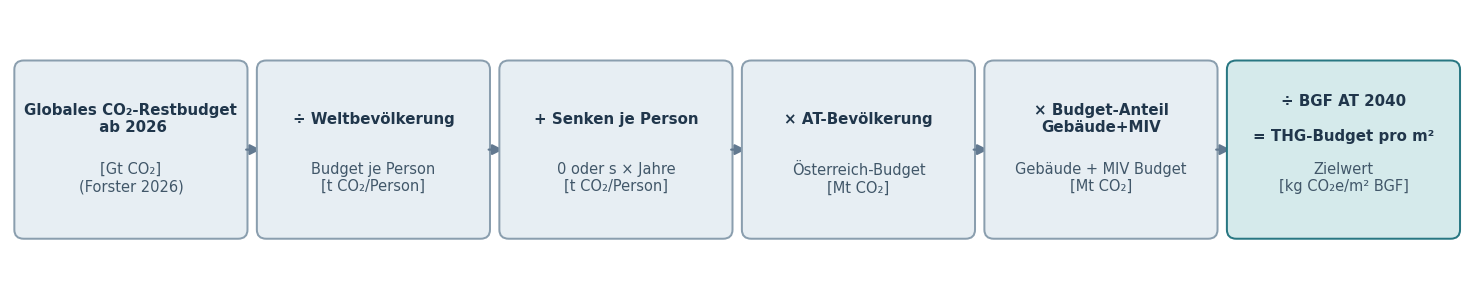

In [ ]:
#| fig-cap: "Schema der THG-Zielwertableitung ab 2026."
#| fig-width: 12
#| fig-height: 2.9
steps = [
    ('Globales CO₂-Restbudget\n ab 2026', '[Gt CO₂]\n(Forster 2026)'),
    ('÷ Weltbevölkerung', 'Budget je Person\n[t CO₂/Person]'),
    ('+ Senken je Person', '0 oder s × Jahre\n[t CO₂/Person]'),
    ('× AT-Bevölkerung', 'Österreich-Budget\n[Mt CO₂]'),
    ('× Budget-Anteil\nGebäude+MIV', 'Gebäude + MIV Budget\n[Mt CO₂]'),
    ('÷ BGF AT 2040\n\n= THG-Budget pro m²', 'Zielwert\n[kg CO₂e/m² BGF]'),
]
fig, ax = plt.subplots(figsize=(12.5, 2.65))
ax.set(xlim=(0, 12.4), ylim=(0, 2.5))
ax.axis('off')
for i, (top, bottom) in enumerate(steps):
    x = 0.10 + i*2.07
    rect = FancyBboxPatch((x, .57),1.83,1.42,boxstyle='round,pad=0.08',
                          fc='#e7eef3' if i<5 else '#d5eaeb',
                          ec='#8a9eae' if i<5 else '#287782',lw=1.2)
    ax.add_patch(rect)
    ax.text(x+.915,1.55,top,ha='center',va='center',fontsize=9.0,weight='bold',color='#20364b')
    ax.text(x+.915,1.03,bottom,ha='center',va='center',fontsize=8.8,color='#415769')
    if i<5:
        ax.add_patch(FancyArrowPatch((x+1.87,1.28),(x+2.05,1.28),
                                     arrowstyle='-|>',mutation_scale=13,color='#627990',lw=1.3))
fig.tight_layout()
plt.show()

## 1. Globale Klimabudgets ab 2026

Die globalen CO₂-Restbudgets gelten ab 1. Januar 2026 und werden aus Tabelle 8 von @forster2026 übernommen. Die ausgewiesenen Einhaltungswahrscheinlichkeiten berücksichtigen ausschließlich die TCRE-Unsicherheit.

In [155]:
# Reihenfolge der Spalten = Einhaltungswahrscheinlichkeit (nur TCRE)
PROBABILITIES = [10, 17, 33, 50, 67, 83, 90]
BUDGET_MATRIX_GT = {
    1.5: [480, 340, 210, 130,  80,  30,  10],
    1.6: [840, 630, 430, 320, 240, 170, 130],
    1.7: [1210,930, 650, 500, 390, 300, 250],
    1.8: [1570,1220,870, 680, 550, 430, 370],
    1.9: [1940,1510,1090,860, 700, 560, 480],
    2.0: [2300,1800,1310,1050,860, 690, 600],
}


In [164]:
#| fig-cap: "Globale CO₂-Restbudgets ab 1.1.2026 [Gt CO₂]"

budget_grid = pd.DataFrame.from_dict(BUDGET_MATRIX_GT, orient='index', columns=PROBABILITIES)
budget_grid.index = budget_grid.index.map(lambda t: f"{t:.1f}")
budget_grid.index.name = 'Temperaturziel [°C]'
budget_grid.columns.name = 'Einhaltungswahrscheinlichkeit [%], nur TCRE'
assert budget_grid.shape == (6,7) and not budget_grid.isna().any().any()
display(budget_grid.style.format('{:,.0f}').background_gradient(axis=None, cmap='Greens'))

"Einhaltungswahrscheinlichkeit [%], nur TCRE",10,17,33,50,67,83,90
Temperaturziel [°C],,,,,,,
1.5,480,340,210,130,80,30,10
1.6,840,630,430,320,240,170,130
1.7,"1,210",930,650,500,390,300,250
1.8,"1,570","1,220",870,680,550,430,370
1.9,"1,940","1,510","1,090",860,700,560,480
2.0,"2,300","1,800","1,310","1,050",860,690,600


## 2. Stellgrößen für die nationale Kalibrierung

Die Bevölkerungszahlen für Österreich und die Welt beziehen sich auf 2023 [@worldbankpopulation].

Der fixe Sektoranteil von 50 % für Gebäude einschließlich MIV entspricht der bisherigen PEQ-Kalibrierung [@schneider2025declaration, Abschnitt 2.3].

Der graduelle Sektoranteil ist eine alternative Kalibrierungsannahme. Als Vergleichswert wird der globale Gebäudeanteil von 37 % nach @alaux2023 herangezogen; dessen Systemgrenze umfasst Lebenszyklusemissionen des Gebäudebestands.

Die zusätzliche Senkenannahme von 1 t CO₂e pro Person und Jahr stammt aus der bisherigen PEQ-Kalibrierung [@schneider2025declaration, Tabelle A1].

::: {.callout-note title="Direkt editierbare Modellannahmen" collapse="false"}
`SECTOR_SHARE_BY_TEMP_XXX` ermöglicht **einen unterschiedlichen Anteil Gebäude + MIV für jede Temperaturstufe**. Der Startwert beträgt überall 50 % (bisherige PEQ-Abgrenzung); alternative Anteile können pro Temperatur geändert werden. Die Senkenannahme `SINK_T_PER_PERSON_A` ist mit 1 t CO₂e/(Person a) angenommen.
:::

In [165]:
#| echo: true
#| code-fold: false
# ===== BASISPARAMETER =====
REFERENCE_YEAR = 2026                   # globales Forster-Budget beginnt am 1.1.2026
MAIN_PROBABILITY = 90                   # nur TCRE-Unsicherheit
POP_AT_2023_PERSONS = 9_131_761         # bisheriger AT/Welt-Datenstand (World Bank 2023)
POP_WORLD_2023_PERSONS = 8_062_923_417  # bisheriger AT/Welt-Datenstand (World Bank 2023)
POP_AT_M = POP_AT_2023_PERSONS / 1e6
POP_WORLD_M = POP_WORLD_2023_PERSONS / 1e6
EPC_SHARE_OVERRIDE = None               # z. B. 0.001 für fixe 0,10 %; None = AT/Welt
SINK_T_PER_PERSON_A = 1.0               # zusätzlich angenommene Senke [t CO₂e/(Person a)]
SINK_END_YEAR = 2075                    # Ende des betrachteten Zeitraums (exklusiv)
GFA_AT_MILLION_M2 = 906.7               # nationale Bruttogrundfläche [Mio. m²]

# ===== TEMPERATURSPEZIFISCHER SEKTORANTEIL =====
# 0.50 = bisherige PEQ-Annahme: Gebäude einschließlich MIV
# 0.37 = alternative Referenzzahl für FOA Buildings nach Alaux (ANDERE Systemgrenze)
SECTOR_SHARE_BY_TEMP_FIXED = {
    1.5: 0.5,
    1.6: 0.5,
    1.7: 0.5,
    1.8: 0.5,
    1.9: 0.5,
    2.0: 0.5,
}
SECTOR_SHARE_BY_TEMP_GRADUAL = {
    1.5: 0.632,
    1.6: 0.549,
    1.7: 0.497,
    1.8: 0.45,
    1.9: 0.421,
    2.0: 0.402,
}



In [166]:

# Farben für alle Diagramme: 1,5 °C grau, 2,0 °C dunkelblau
TEMP_COLORS = {
    1.5: "#637BFF", 1.6: "#77c2ff", 1.7: "#a1ffe7",
    1.8: "#6bfcac", 1.9: "#4fb44b", 2.0: "#1f8112",
}

EPC_SHARE = (POP_AT_2023_PERSONS / POP_WORLD_2023_PERSONS
             if EPC_SHARE_OVERRIDE is None else EPC_SHARE_OVERRIDE)
SINK_YEARS = SINK_END_YEAR - REFERENCE_YEAR

print(f'Bevölkerungsanteil Österreich: {100*EPC_SHARE:.4f} %')
print(f'Senken: {SINK_T_PER_PERSON_A:g} t/(Person·a), {SINK_YEARS} Jahre ({REFERENCE_YEAR}–{SINK_END_YEAR})')
print(f'Bezugsfläche: {GFA_AT_MILLION_M2:.1f} Mio. m² BGF')
SECTOR_SHARES = {
    "Fix 50 %": SECTOR_SHARE_BY_TEMP_FIXED,
    "Graduell": SECTOR_SHARE_BY_TEMP_GRADUAL,
}

display(pd.DataFrame({
    "Temperatur [°C]": list(SECTOR_SHARE_BY_TEMP_FIXED),
    "Fix [%]": [100*v for v in SECTOR_SHARE_BY_TEMP_FIXED.values()],
    "Graduell [%]": [100*v for v in SECTOR_SHARE_BY_TEMP_GRADUAL.values()],
}).style.format(precision=1))

Bevölkerungsanteil Österreich: 0.1133 %
Senken: 1 t/(Person·a), 49 Jahre (2026–2075)
Bezugsfläche: 906.7 Mio. m² BGF


,Temperatur [°C],Fix [%],Graduell [%]
0,1.5,50.0,63.2
1,1.6,50.0,54.9
2,1.7,50.0,49.7
3,1.8,50.0,45.0
4,1.9,50.0,42.1
5,2.0,50.0,40.2


## 3. Formel und Einheiten

Mit dem globalen Restbudget $B_{\mathrm{glob}}(T,p)$ in **Gt CO₂**, der Welt- und österreichischen Bevölkerung in **Mio. Personen** und der zusätzlichen jährlichen Senkenannahme $s$ in **t CO₂e/(Person·a)**:

$$
\begin{aligned}
b_{\mathrm{Welt,pc}}(T,p) &= \frac{1000\,B_{\mathrm{glob}}(T,p)}{P_{\mathrm{Welt}}} && [\mathrm{t\ CO_2/Person}],\\
b_{\mathrm{AT,pc}}(T,p,s) &= b_{\mathrm{Welt,pc}}(T,p) + s\cdot N_{\mathrm{Senkenjahre}} && [\mathrm{t\ CO_2(e)/Person}],\\
B_{\mathrm{AT}}(T,p,s) &= P_{\mathrm{AT}}\,b_{\mathrm{AT,pc}}(T,p,s) && [\mathrm{Mt\ CO_2(e)}],\\
B_{\mathrm{Geb+MIV}}(T,p,s) &= \alpha(T)\,B_{\mathrm{AT}}(T,p,s) && [\mathrm{Mt\ CO_2(e)}],\\
\boxed{z_{\mathrm{THG}}(T,p,s)} &= \frac{1000\,B_{\mathrm{Geb+MIV}}(T,p,s)}{A_{\mathrm{BGF}}} && [\mathrm{kg\ CO_2e/m^2\ BGF}].
\end{aligned}
$$

:::{.callout-note title="Ab 2026 kein zusätzlicher historischer Abzug"}
Das globale Ausgangsbudget ist bereits für Anfang 2026 angegeben. Eine Fortschreibung auf spätere Jahre benötigte neue Emissionsdaten.
:::

In [168]:

SECTOR_SHARES = {
    "Budget-Anteil Gebäude+MIV: Fix 50 %": SECTOR_SHARE_BY_TEMP_FIXED,
    "Budget-Anteil Gebäude+MIV: Graduell": SECTOR_SHARE_BY_TEMP_GRADUAL,
}


def calculate_target(temp, probability, sink_rate, model="Fix 50 %"):
    temp = round(float(temp), 1)
    global_gt = BUDGET_MATRIX_GT[temp][PROBABILITIES.index(probability)]

    at_mt = global_gt * 1000 * EPC_SHARE
    sinks_mt = POP_AT_M * sink_rate * SINK_YEARS
    sector_share = SECTOR_SHARES[model][temp]
    sector_mt = (at_mt + sinks_mt) * sector_share

    return {
        "Sektorvariante": model,
        "Temperatur [°C]": temp,
        "Wahrscheinlichkeit [%]": probability,
        "Global [Gt CO₂]": global_gt,
        "Pro Person global [t CO₂]": at_mt / POP_AT_M,
        "Österreich ohne Senken [Mt CO₂]": at_mt,
        "Senken Österreich [Mt CO₂e]": sinks_mt,
        "Österreich gesamt [Mt CO₂(e)]": at_mt + sinks_mt,
        "Sektoranteil [%]": sector_share * 100,
        "Gebäude + MIV [Mt CO₂(e)]": sector_mt,
        "THG-Ziel [kg CO₂e/m² BGF]": 1000 * sector_mt / GFA_AT_MILLION_M2,
        "Senkenrate [t/(Pers·a)]": sink_rate,
    }


results = pd.DataFrame([
    {**calculate_target(t, p, sink, model), "Variante": label}
    for model in SECTOR_SHARES
    for t in sorted(BUDGET_MATRIX_GT)
    for p in PROBABILITIES
    for label, sink in [
        ("ohne Senken", 0.0),
        ("mit Senken", SINK_T_PER_PERSON_A)
    ]
])

print(f"{len(results)} Szenarien berechnet")


168 Szenarien berechnet


## 4. Hauptvariante: 90 % Zielerreichung (nur TCRE)

Der **volle Balken** zeigt den Zielwert ohne zusätzliche natürliche Senken. Der hellere Teil ergänzt die mit `SINK_T_PER_PERSON_A` angenommene Senkenleistung bis zum Endjahr. Der individuelle Sektoranteil $\alpha(T)$ steht unmittelbar neben dem Temperaturziel.

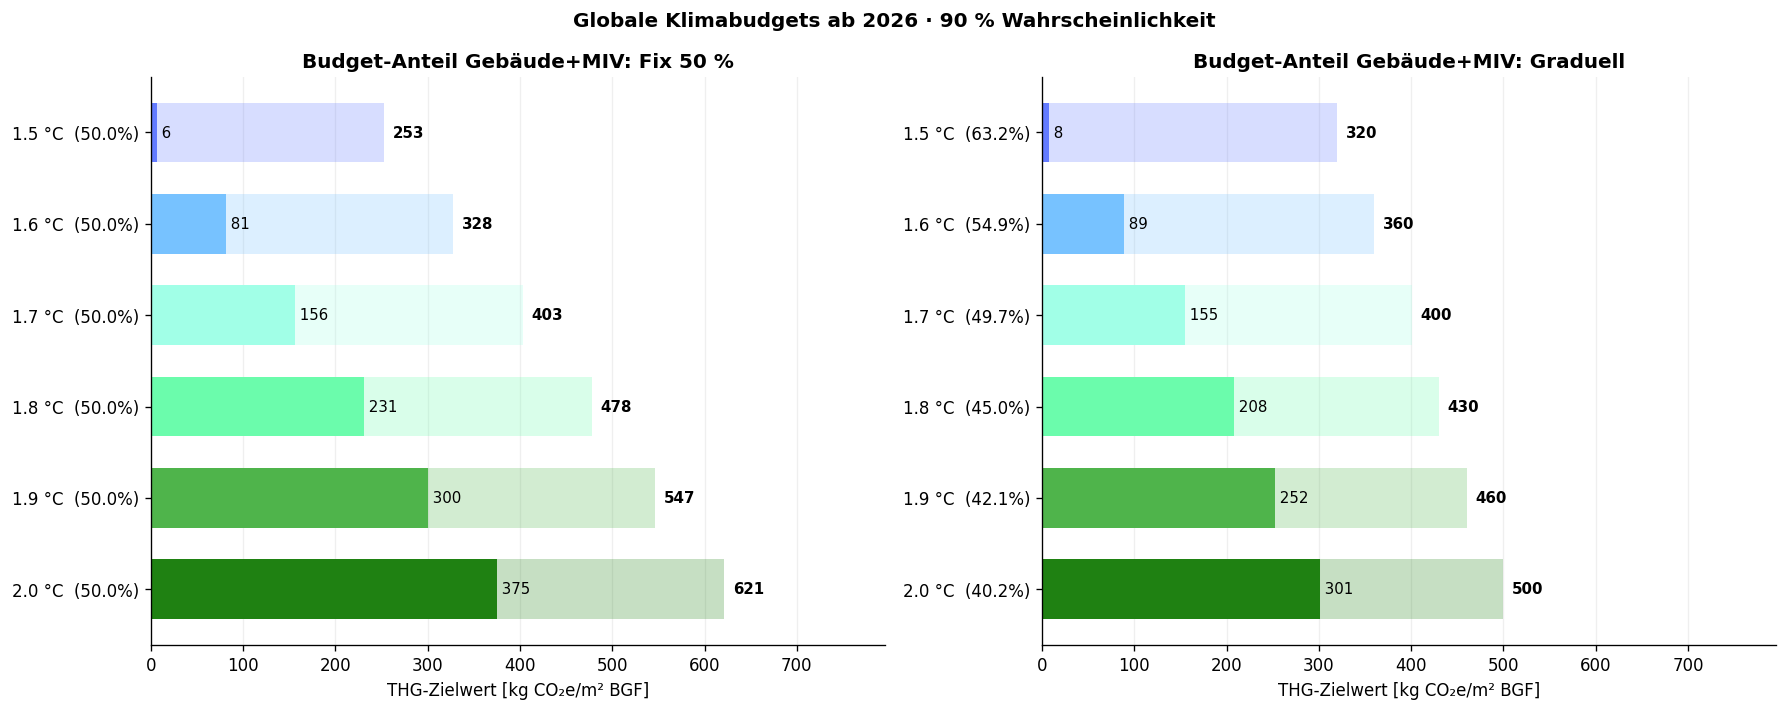

In [ ]:

#| label: fig-thg-90
#| fig-cap: "Flächenspezifische THG-Budgets für 90 % Einhaltungswahrscheinlichkeit (nur TCRE). Eigene Berechnung auf Basis von @forster2026."
#| fig-width: 15
#| fig-height: 6

main = results[results["Wahrscheinlichkeit [%]"] == MAIN_PROBABILITY]
temps = sorted(BUDGET_MATRIX_GT)
y = np.arange(len(temps))

fig, axs = plt.subplots(1, 2, figsize=(15, 6), sharex=True)
max_value = main["THG-Ziel [kg CO₂e/m² BGF]"].max()
min_value = main["THG-Ziel [kg CO₂e/m² BGF]"].min()

for ax, (model, shares) in zip(axs, SECTOR_SHARES.items()):
    df = main[main["Sektorvariante"] == model].pivot(
        index="Temperatur [°C]",
        columns="Variante",
        values="THG-Ziel [kg CO₂e/m² BGF]"
    ).reindex(temps)

    colors = [TEMP_COLORS[t] for t in temps]

    ax.barh(y, df["mit Senken"], color=colors, alpha=0.25, height=0.65)
    ax.barh(y, df["ohne Senken"], color=colors, height=0.65)

    for i, t in enumerate(temps):
        v0, v1 = df.loc[t, ["ohne Senken", "mit Senken"]]
        ax.text(v0 + min_value*0.015, i, f" {v0:.0f}",
                va="center", fontsize=9)
        ax.text(v1 + max_value*0.015, i, f"{v1:.0f}",
                va="center", fontsize=9, fontweight="bold")

    ax.set_yticks(y, [f"{t:.1f} °C  ({shares[t]:.1%})" for t in temps])
    ax.invert_yaxis()
    ax.set_xlim(0, max_value*1.28)
    ax.set_title(model, fontweight="bold")
    ax.set_xlabel("THG-Zielwert [kg CO₂e/m² BGF]")
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

fig.suptitle(f"Globale Klimabudgets ab 2026 · {MAIN_PROBABILITY} % Wahrscheinlichkeit",
             fontweight="bold")
fig.tight_layout()
plt.show()

display(
    main.pivot_table(
        index="Temperatur [°C]",
        columns=["Sektorvariante", "Variante"],
        values="THG-Ziel [kg CO₂e/m² BGF]"
    ).style.format("{:.1f}")
)


## 5. Sensitivität: alle sieben Wahrscheinlichkeiten

**Zweites Ergebnisdiagramm:** 10, 17, 33, 50, 67, 83 und 90 % der Forster-Tabelle. Oben ohne zusätzliche Senken, unten mit der gewählten Senkenannahme. Links mit fixen Gebäude-MIV Budget-Anteil, rechts graduell. Jede Temperatur hat in beiden Darstellungen dieselbe Farbe.

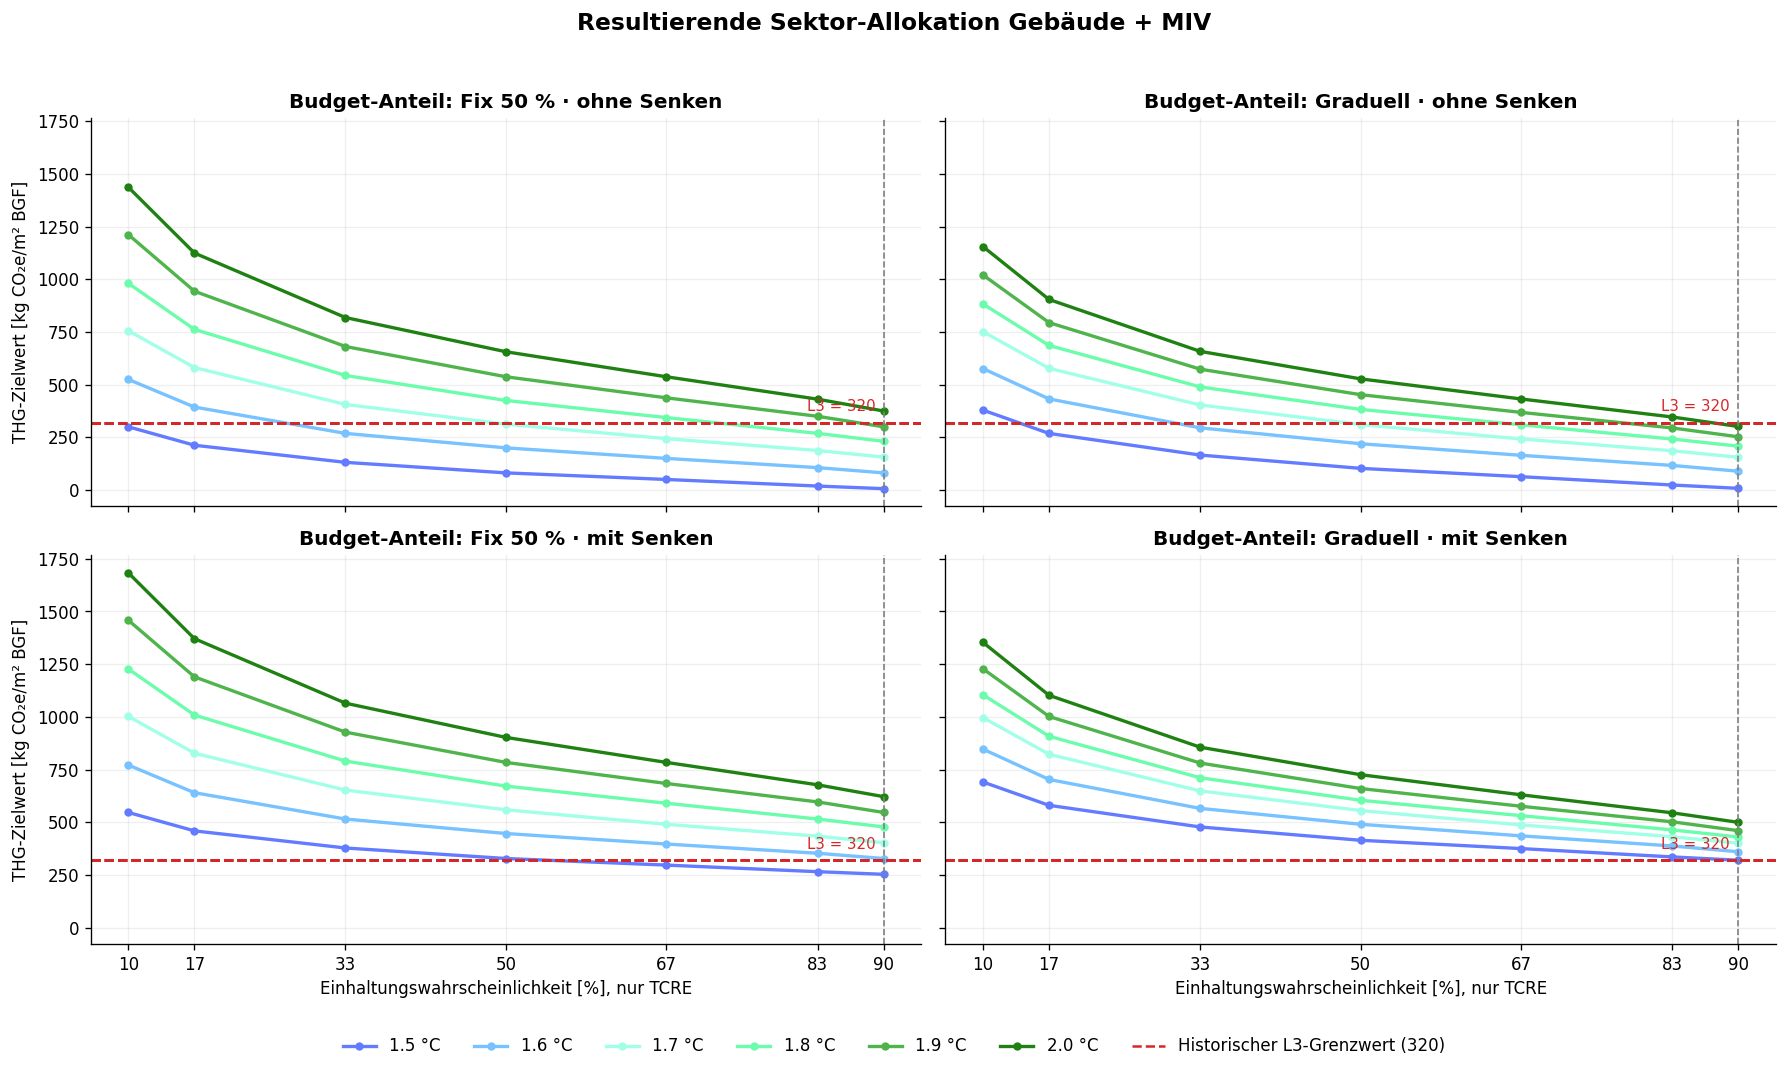

In [ ]:
#| label: fig-thg-sensitivitaet
#| fig-cap: "Sensitivität der THG-Zielwerte gegenüber Temperaturziel, Wahrscheinlichkeit, Senken und Sektorallokation. Budgetbasis: @forster2026."
#| fig-width: 15
#| fig-height: 9

fig, axs = plt.subplots(2, 2, figsize=(15, 9), sharex=True, sharey=True)

for col, model in enumerate(SECTOR_SHARES):
    for row, variante in enumerate(["ohne Senken", "mit Senken"]):
        ax = axs[row, col]
        df = results[
            (results["Sektorvariante"] == model) &
            (results["Variante"] == variante)
        ]

        for t in sorted(BUDGET_MATRIX_GT):
            data = df[df["Temperatur [°C]"] == t].sort_values(
                "Wahrscheinlichkeit [%]"
            )
            ax.plot(
                data["Wahrscheinlichkeit [%]"],
                data["THG-Ziel [kg CO₂e/m² BGF]"],
                "-o", color=TEMP_COLORS[t], lw=2,
                markersize=4, label=f"{t:.1f} °C"
            )
            ax.axhline(
                320, color="#d62728", linestyle="--", linewidth=1.5
            )

        ax.axvline(MAIN_PROBABILITY, color="gray", ls="--", lw=1)
        ax.set_title(f"{model.replace(" Gebäude+MIV", "")} · {variante}", fontweight="bold")
        ax.set_xticks(PROBABILITIES)
        ax.grid(alpha=0.2)

        ax.annotate(
            "L3 = 320",
            xy=(90, 320), xytext=(-5, 5),
            textcoords="offset points",
            ha="right", va="bottom", color="#d62728", fontsize=9
        )

        if row == 1:
            ax.set_xlabel("Einhaltungswahrscheinlichkeit [%], nur TCRE")
        if col == 0:
            ax.set_ylabel("THG-Zielwert [kg CO₂e/m² BGF]")

from matplotlib.lines import Line2D

handles, labels = axs[0, 0].get_legend_handles_labels()

handles.append(
    Line2D([0], [0], color="#d62728", linestyle="--",
           linewidth=1.5, label="Historischer L3-Grenzwert (320)")
)

fig.legend(
    handles=handles,
    loc="lower center",
    ncol=7,
    bbox_to_anchor=(0.5, 0),
    frameon=False
)
fig.suptitle("Resultierende Sektor-Allokation Gebäude + MIV",
             fontsize=14, fontweight="bold")
fig.tight_layout(rect=(0, 0.05, 1, 0.96))
plt.show()


## 6. Unterschiede in der BGF

Beispielrechnung für **2,0 °C / 90 %** mit beiden Senkenvarianten und beiden Allokationsmodellen (Fix und Graduell). Die BGF-Alternativen sind als Sensitivität verfügbar; die Standardkalibrierung bleibt auf **906,7 Mio. m² BGF** bezogen.

In [170]:

# Vergleich der Rechenmodelle: fix vs. graduell
selected = pd.DataFrame([
    calculate_target(2.0, MAIN_PROBABILITY, sink, model)
    for model in SECTOR_SHARES
    for sink in [0.0, SINK_T_PER_PERSON_A]
])

selected["Senkenvariante"] = [
    "ohne Senken", "mit Senken"
] * len(SECTOR_SHARES)

print("THG-Zielwerte – 2,0 °C, 90 % Wahrscheinlichkeit:")
display(
    selected.set_index(["Sektorvariante", "Senkenvariante"])[[
        "Global [Gt CO₂]",
        "Pro Person global [t CO₂]",
        "Senken Österreich [Mt CO₂e]",
        "Österreich gesamt [Mt CO₂(e)]",
        "Sektoranteil [%]",
        "Gebäude + MIV [Mt CO₂(e)]",
        "THG-Ziel [kg CO₂e/m² BGF]"
    ]].round(2)
)

# Sensitivität gegenüber der nationalen Bezugsfläche
BGF_VARIANTS = {
    "THG-Referenz 2040": 906.7,
    "Statistikbezug 2021": 1058.935,
    "Building Sector Pool heute": 1112.341,
    "Building Sector Pool 2040": 1126.579,
}

bgf_comparison = pd.DataFrame([
    {
        "Rechenmodell": model,
        "Flächenvariante": name,
        "BGF [Mio. m²]": area,
        "Sektoranteil [%]": case["Sektoranteil [%]"],
        "Zielwert [kg CO₂e/m² BGF]":
            1000 * case["Gebäude + MIV [Mt CO₂(e)]"] / area,
    }
    for model in SECTOR_SHARES
    for case in [calculate_target(
        2.0, MAIN_PROBABILITY, SINK_T_PER_PERSON_A, model
    )]
    for name, area in BGF_VARIANTS.items()
])

print("Flächenvarianten – beide Rechenmodelle mit Senken:")
display(
    bgf_comparison.pivot(
        index=["Flächenvariante", "BGF [Mio. m²]"],
        columns="Rechenmodell",
        values="Zielwert [kg CO₂e/m² BGF]"
    ).round(1)
)


THG-Zielwerte – 2,0 °C, 90 % Wahrscheinlichkeit:


Global [Gt CO₂]  \
Sektorvariante                      Senkenvariante                    
Budget-Anteil Gebäude+MIV: Fix 50 % ohne Senken                 600   
                                    mit Senken                  600   
Budget-Anteil Gebäude+MIV: Graduell ohne Senken                 600   
                                    mit Senken                  600   

                                                    Pro Person global [t CO₂]  \
Sektorvariante                      Senkenvariante                              
Budget-Anteil Gebäude+MIV: Fix 50 % ohne Senken                         74.41   
                                    mit Senken                          74.41   
Budget-Anteil Gebäude+MIV: Graduell ohne Senken                         74.41   
                                    mit Senken                          74.41   

                                                    Senken Österreich [Mt CO₂e]  \
Sektorvariante                      Senkenvariante                                
Budget-Anteil Gebäude+MIV: Fix 50 % ohne Senken                            0.00   
                                    mit Senken                           447.46   
Budget-Anteil Gebäude+MIV: Graduell ohne Senken                            0.00   
                                    mit Senken                           447.46   

                                                    Österreich gesamt [Mt CO₂(e)]  \
Sektorvariante                      Senkenvariante                                  
Budget-Anteil Gebäude+MIV: Fix 50 % ohne Senken                            679.54   
                                    mit Senken                            1126.99   
Budget-Anteil Gebäude+MIV: Graduell ohne Senken                            679.54   
                                    mit Senken                            1126.99   

                                                    Sektoranteil [%]  \
Sektorvariante                      Senkenvariante                     
Budget-Anteil Gebäude+MIV: Fix 50 % ohne Senken                 50.0   
                                    mit Senken                  50.0   
Budget-Anteil Gebäude+MIV: Graduell ohne Senken                 40.2   
                                    mit Senken                  40.2   

                                                    Gebäude + MIV [Mt CO₂(e)]  \
Sektorvariante                      Senkenvariante                              
Budget-Anteil Gebäude+MIV: Fix 50 % ohne Senken                        339.77   
                                    mit Senken                         563.50   
Budget-Anteil Gebäude+MIV: Graduell ohne Senken                        273.17   
                                    mit Senken                         453.05   

                                                    THG-Ziel [kg CO₂e/m² BGF]  
Sektorvariante                      Senkenvariante                             
Budget-Anteil Gebäude+MIV: Fix 50 % ohne Senken                        374.73  
                                    mit Senken                         621.48  
Budget-Anteil Gebäude+MIV: Graduell ohne Senken                        301.28  
                                    mit Senken                         499.67

Flächenvarianten – beide Rechenmodelle mit Senken:


,Rechenmodell,Budget-Anteil Gebäude+MIV: Fix 50 %,Budget-Anteil Gebäude+MIV: Graduell
Flächenvariante,BGF [Mio. m²],,
Building Sector Pool 2040,1126.579,500.2,402.1
Building Sector Pool heute,1112.341,506.6,407.3
Statistikbezug 2021,1058.935,532.1,427.8
THG-Referenz 2040,906.700,621.5,499.7


::: {.callout-note title="Alaux (2023): 37 % als alternative sektorale Referenz" collapse="true"}
Alaux et al. (2023) diskutieren einen Budgetanteil von **37 % für das globale *Field of Action Buildings***, einschließlich Lebenszyklus-/Embodied-Emissionen. Diese Systemgrenze unterscheidet sich von der hier eingestellten PEQ-Allokation **Gebäude + MIV**.
:::

::: {.callout-warning title="Unsicherheiten" collapse="true"}
- Forster (2026) bilanziert **CO₂**; Zielwerte der Quartiers-LCA werden als **CO₂e** angegeben. Die Übertragung braucht eine konsistente Behandlung von Nicht-CO₂-Gasen.
- Zusätzliche natürliche Senken erhöhen hier das rechnerische Bruttobudget. **Nur zusätzlich wirksame, nicht bereits im globalen Nettobudget enthaltene Entnahmen** dürfen ohne Doppelzählung angesetzt werden.
- Die **90-%-Angabe** berücksichtigt ausschließlich TCRE-Unsicherheit (TCRE=Transient Climate Response to Cumulative Carbon Emissions beschreibt, wie stark sich die globale Mitteltemperatur infolge einer bestimmten Menge kumulierter CO₂-Emissionen erhöht. Die Unsicherheit dahingehend beinhaltet nicht ZEC (Zero Emissions Commitment): 
    - Zusätzliche Erwärmung oder Abkühlung nach Erreichen von Netto-Null-CO₂-Emissionen, 
    - Nicht-CO₂-Treibhausgase: Unsicherheiten hinsichtlich künftiger Methan-, Lachgas- und Aerosolemissionen und ihrer Klimawirkung,  
    - Erdsystem-Rückkopplungen: Beispielsweise zusätzliche Emissionen durch auftauende Permafrostböden)
- Bevölkerungsrelation AT/Welt stammt aus **2023**, während die Klimabudgets **ab 2026** gelten.
- 50 % Gebäude + MIV und 906,7 Mio. m² BGF sind **bestehende PEQ-Annahmen** und können geändert werden.
:::

## 7. Rechenkontrollen

In [173]:

# ===== RECHENKONTROLLE =====
import math
from pathlib import Path

temps = sorted(BUDGET_MATRIX_GT)
models = list(SECTOR_SHARES)
expected = len(temps) * len(PROBABILITIES) * 2 * len(models)

# 1. Ausgangsdaten und Szenarioanzahl
assert budget_grid.shape == (6, 7)
assert len(results) == expected
assert set(results["Sektorvariante"]) == set(models)
assert results["THG-Ziel [kg CO₂e/m² BGF]"].ge(0).all()

for t in temps:
    budgets = BUDGET_MATRIX_GT[t]
    assert all(a >= b for a, b in zip(budgets, budgets[1:]))

    for model in models:
        for p in PROBABILITIES:
            a = calculate_target(t, p, 0.0, model)
            b = calculate_target(t, p, SINK_T_PER_PERSON_A, model)

            # 2. Nationale Allokation: Gt -> Mt -> Österreich
            assert math.isclose(
                a["Österreich ohne Senken [Mt CO₂]"],
                a["Global [Gt CO₂]"] * 1000 * EPC_SHARE,
                rel_tol=1e-12
            )

            # 3. Senken erhöhen oder erhalten das Budget
            assert b["THG-Ziel [kg CO₂e/m² BGF]"] >= a[
                "THG-Ziel [kg CO₂e/m² BGF]"
            ]

            for case in (a, b):
                # 4. Temperaturspezifischer Sektoranteil
                assert math.isclose(
                    case["Sektoranteil [%]"],
                    100 * SECTOR_SHARES[model][t],
                    rel_tol=1e-12
                )

                # 5. Sektorbudget und flächenspezifischer Zielwert
                assert math.isclose(
                    case["Gebäude + MIV [Mt CO₂(e)]"],
                    case["Österreich gesamt [Mt CO₂(e)]"]
                    * SECTOR_SHARES[model][t],
                    rel_tol=1e-12
                )
                assert math.isclose(
                    case["THG-Ziel [kg CO₂e/m² BGF]"],
                    1000 * case["Gebäude + MIV [Mt CO₂(e)]"]
                    / GFA_AT_MILLION_M2,
                    rel_tol=1e-12
                )

# 6. Eindeutigkeit aller Szenarien
assert not results.duplicated([
    "Sektorvariante", "Temperatur [°C]",
    "Wahrscheinlichkeit [%]", "Variante"
]).any()

print(
    f"Rechenkontrolle bestanden: "
    f"{len(temps) * len(PROBABILITIES)} Ausgangsbudgets, "
    f"{len(models)} Sektormodelle, "
    f"{len(results)} Ergebnisfälle."
)

# ===== EXPORT =====
EXPORT = Path("forster2026_thg_szenarien.csv")
results.to_csv(
    EXPORT, sep=";", decimal=",",
    index=False, encoding="utf-8-sig"
)
print("Ergebnistabelle:", EXPORT.resolve())


Rechenkontrolle bestanden: 42 Ausgangsbudgets, 2 Sektormodelle, 168 Ergebnisfälle.
Ergebnistabelle: C:\Users\schneids\code\peq-higrube\peq-higrube\Berechnungen\thg_budget\forster2026_thg_szenarien.csv



## Literaturverzeichnis {#refs}